# Task 1 · Cache Reuse Rule
**Owner:** Naveena Sivapuram · DSA 4

Which matching rule saves the most LLM calls without reusing answers for look-alike questions?

Kaggle settings: **GPU T4** (only for the embeddings), **Internet on**. Add Input → **dsa4-data** and **dsa4-cache**.


## 1. Introduction

Calling an LLM for every question can be costly and slow, so a semantic cache can reduce this cost by reusing answers to previously asked, similar questions. However, this creates a risk: a look-alike question may have almost the same wording as an earlier question but require a different answer. This task investigates: **Which matching rule saves the most LLM calls without reusing answers for look-alike questions, and can its error rate be guaranteed?**

Our hypothesis is that similarity alone cannot separate paraphrases from look-alikes; adding entity, date and number mismatch signals (V5, V6) cuts unsafe reuse more than any embedder change; a fine-tuned embedder with mined hard negatives is the best single embedder. We use TriviaQA and HotpotQA, with paraphrases that preserve the answer and look-alikes that mostly change an entity, date or number. These variants are generated using **Qwen2.5-7B-Instruct**. The current experiment covers Block 1 (492 questions); the full dataset of 2,000 questions will be used later.

Our approach builds on four papers: Bang (2023) for the fixed-threshold cache baseline, Ghaffari et al. (2025) for ensemble embeddings, Schroeder et al. (2026) for per-entry thresholds with an error bound, and Zhang et al. (2026) for showing how look-alike inputs can fool similarity-based caches. We evaluate how many LLM calls each rule saves while keeping unsafe reuse at or below 2%. Thresholds are selected on the validation set, and final results are reported on the test set, averaged over three random splits (seeds 0–2), with mean ± standard deviation.


## 2. Setup and data

In [1]:
# Setup: clone the team repository and install what Kaggle lacks
import os, subprocess, sys
REPO_URL = "https://github.com/Naveena126/dsa4-reuse-retrieve-generate.git"
if not os.path.exists("/kaggle/working/repo"):
    subprocess.run(["git", "clone", "-q", REPO_URL, "/kaggle/working/repo"], check=True)
else:
    subprocess.run(["git", "-C", "/kaggle/working/repo", "pull", "-q"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu", "bitsandbytes>=0.43"], check=True)
os.chdir("/kaggle/working/repo")
sys.path.insert(0, "src")
import glob
def find_input(name):
    # Kaggle mounts datasets at /kaggle/input/<name> or /kaggle/input/datasets/<owner>/<name>
    hits = [h for h in glob.glob(f"/kaggle/input/**/{name}", recursive=True) if os.path.isdir(h)]
    if not hits:
        raise FileNotFoundError(f"Add the dataset {name} with Add Input")
    return hits[0]
print("ready")

ready


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from dsa4 import data, stream, reuse

DATA = find_input("dsa4-data")
CACHE = glob.glob(find_input("dsa4-cache") + "/**/cache.jsonl", recursive=True)[0]
MET, FIG = Path("results/metrics"), Path("results/figures")
MET.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

q = data.load_questions(DATA)
cache = pd.read_json(CACHE, lines=True)
cache = cache[cache["variants"].notna()]          # questions whose variants were generated
var = stream.variants_table(cache)
q = q[q["qid"].isin(cache["qid"])].reset_index(drop=True)
print(len(q), "source questions;", var["kind"].value_counts().to_dict())

492 source questions; {'paraphrase': 984, 'lookalike': 492}


In [3]:
# Drop look-alikes that Qwen returned unchanged (identical to the source or to a paraphrase)
from dsa4.text import normalize
src_norm = dict(zip(q["qid"], q["question"].map(normalize)))
para_norm = var[var["kind"] == "paraphrase"].groupby("qid")["text"].apply(lambda s: set(map(normalize, s)))
is_copy = var.apply(lambda r: r["kind"] == "lookalike" and
                    (normalize(r["text"]) == src_norm.get(r["qid"]) or
                     normalize(r["text"]) in para_norm.get(r["qid"], set())), axis=1)
print(int(is_copy.sum()), "look-alikes identical to their source or a paraphrase; dropped")
var = var[~is_copy].reset_index(drop=True)

16 look-alikes identical to their source or a paraphrase; dropped


In [4]:
# Drop variants where Qwen leaked the answer into the question
leak = var["text"].str.contains(r"\(answer", case=False)
print(leak.sum(), "variants with a leaked answer; dropped")
var = var[~leak].reset_index(drop=True)

4 variants with a leaked answer; dropped


## 3. Data exploration

In [5]:
acc = pd.DataFrame({"dataset": cache["dataset"], "direct": cache["direct"].str["correct"],
                    "rag": cache["rag"].str["correct"]})
display(acc.groupby("dataset")[["direct", "rag"]].mean().round(3).rename(columns=lambda c: c + " accuracy"))
display(var[var["kind"] == "lookalike"]["changed"].value_counts().rename("look-alikes by type of change"))
pd.set_option("display.max_colwidth", 90)
ex = var[var["qid"] == var["qid"].iloc[0]]
print("Source:", q.set_index("qid").loc[ex["qid"].iloc[0], "question"])
display(ex[["kind", "text"]])

,direct accuracy,rag accuracy
dataset,,
hotpotqa,0.191,0.488
triviaqa,0.537,0.724


changed
entity    354
date       80
number     29
other       9
Name: look-alikes by type of change, dtype: int64

Source: Kagoshima international airport is in which country?


,kind,text
0,paraphrase,Which country does Kagoshima International Airport belong to?
1,paraphrase,Identify the country where Kagoshima International Airport is located.
2,lookalike,Kagoshima international airport is in which continent?


**Variant quality.** Variants were filtered automatically: 16 look-alikes identical to their source or a paraphrase and 4 variants that contained the answer were removed. They were not checked by hand, so some paraphrases may change the meaning and some look-alikes may not change the answer. Both would make the unsafe-reuse figures less exact.

## 4. Embeddings

Every source question and variant is embedded once with each model (normalised vectors, so the dot product is the cosine similarity).

In [6]:
from sentence_transformers import SentenceTransformer

texts = pd.concat([q[["qid", "question"]].rename(columns={"question": "text"}).assign(vid=q["qid"]),
                   var[["vid", "text"]]], ignore_index=True).drop_duplicates("vid")
MODELS = {"minilm": "sentence-transformers/all-MiniLM-L6-v2", "bge": "BAAI/bge-base-en-v1.5"}
EMB = {}
for name, mid in MODELS.items():
    m = SentenceTransformer(mid)
    v = m.encode(texts["text"].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
    EMB[name] = dict(zip(texts["vid"], v.astype("float32")))
print({k: len(v) for k, v in EMB.items()})

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (19 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

{'minilm': 1948, 'bge': 1948}


## 5. Method

The stream replays each split's source questions, then their paraphrases and look-alikes at random later positions. A query reuses the closest cached entry if the rule says so; otherwise it is answered and stored. A reuse is **safe** only if both questions have the same correct answer.

- **calls saved** = reuses ÷ all queries
- **unsafe reuse** = unsafe reuses ÷ all reuses (our 2% target)
- **safe recall** = safe reuses ÷ queries that had a safe entry available

Thresholds are chosen on the validation split (most calls saved with unsafe reuse ≤ 2%) and reported on the test split, over seeds 0, 1 and 2.

In [7]:
THRESH = np.round(np.arange(0.60, 1.0001, 0.01), 2)
TARGET = 0.02
RULES = {"V1 MiniLM": "minilm", "V1 bge": "bge", "V2 ensemble": "ensemble"}

def make_stream(seed, split, datasets=("triviaqa", "hotpotqa"), repeat=0.0):
    src = q[(q[f"split_s{seed}"] == split) & q["dataset"].isin(datasets)]
    return stream.build_stream(src[["qid", "question"]], var[var["qid"].isin(src["qid"])],
                               repeat_rate=repeat, seed=seed)

def sim_for(s, rule):
    if rule == "ensemble":
        return (sim_for(s, "minilm") + sim_for(s, "bge")) / 2
    return reuse.similarity_matrix(np.stack([EMB[rule][v] for v in s["vid"]]))

s = make_stream(0, "val")
print(len(s), "events in the seed-0 validation stream:", s["kind"].value_counts().to_dict())

393 events in the seed-0 validation stream: {'paraphrase': 198, 'source': 99, 'lookalike': 96}


## 6. Results: exact match, V1 and V2

In [8]:
rows, curves = [], {}
for seed in (0, 1, 2):
    sv, st = make_stream(seed, "val"), make_stream(seed, "test")
    rows.append({"rule": "V0 exact match", "seed": seed, "threshold": np.nan,
                 **reuse.summarise(reuse.simulate_exact(st))})
    for label, rule in RULES.items():
        cv = reuse.sweep(sv, sim_for(sv, rule), THRESH)
        curves[(label, seed)] = cv
        t = reuse.pick_threshold(cv, TARGET)
        rows.append({"rule": label, "seed": seed, "threshold": t,
                     **reuse.summarise(reuse.simulate(st, sim_for(st, rule), t))})
res = pd.DataFrame(rows)
res.to_csv(MET / "task1_results_by_seed.csv", index=False)
summary = res.groupby("rule")[["threshold", "calls_saved", "unsafe_reuse", "safe_recall"]].agg(["mean", "std"]).round(3)
summary.to_csv(MET / "task1_summary.csv")
summary

threshold      calls_saved      unsafe_reuse      safe_recall  \
                    mean  std        mean  std         mean  std        mean   
rule                                                                           
V0 exact match       NaN  NaN         0.0  0.0          0.0  0.0         0.0   
V1 MiniLM            1.0  0.0         0.0  0.0          0.0  0.0         0.0   
V1 bge               1.0  0.0         0.0  0.0          0.0  0.0         0.0   
V2 ensemble          1.0  0.0         0.0  0.0          0.0  0.0         0.0   

                     
                std  
rule                 
V0 exact match  0.0  
V1 MiniLM       0.0  
V1 bge          0.0  
V2 ensemble     0.0

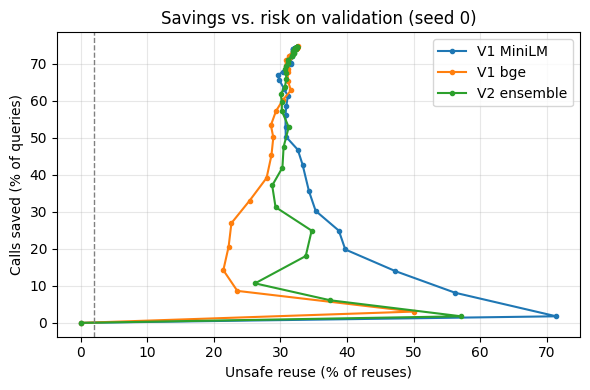

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for label in RULES:
    cv = curves[(label, 0)]
    ax.plot(cv["unsafe_reuse"] * 100, cv["calls_saved"] * 100, marker=".", label=label)
ax.axvline(TARGET * 100, color="grey", ls="--", lw=1)
ax.set_xlabel("Unsafe reuse (% of reuses)"); ax.set_ylabel("Calls saved (% of queries)")
ax.set_title("Savings vs. risk on validation (seed 0)"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIG / "task1_savings_vs_risk.png", dpi=150)

mean    25%    50%    75%
model  kind                                  
bge    lookalike   0.905  0.874  0.924  0.952
       paraphrase  0.920  0.892  0.934  0.965
minilm lookalike   0.893  0.851  0.920  0.967
       paraphrase  0.901  0.878  0.924  0.955

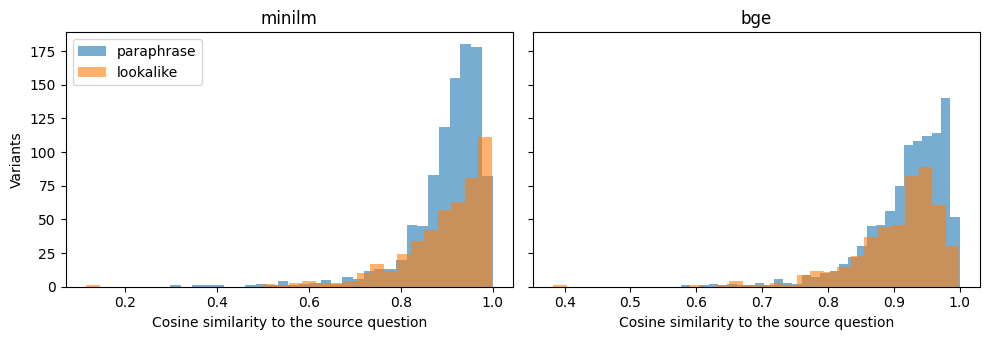

In [10]:
# Why thresholds fail: similarity of each variant to its own source question
rows = []
for name in ("minilm", "bge"):
    for r in var.itertuples():
        rows.append({"model": name, "kind": r.kind, "sim": float(EMB[name][r.vid] @ EMB[name][r.qid])})
sims = pd.DataFrame(rows)
display(sims.groupby(["model", "kind"])["sim"].describe()[["mean", "25%", "50%", "75%"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, name in zip(axes, ("minilm", "bge")):
    for kind in ("paraphrase", "lookalike"):
        ax.hist(sims[(sims["model"] == name) & (sims["kind"] == kind)]["sim"], bins=30, alpha=.6, label=kind)
    ax.set_title(name); ax.set_xlabel("Cosine similarity to the source question")
axes[0].set_ylabel("Variants"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "task1_similarity_by_kind.png", dpi=150)

In [11]:
# Same rules on a stream where 20% of queries are exact repeats
rows20 = []
for seed in (0, 1, 2):
    st = make_stream(seed, "test", repeat=0.2)
    for label, rule in RULES.items():
        t = res[(res["rule"] == label) & (res["seed"] == seed)]["threshold"].iloc[0]
        rows20.append({"rule": label, "seed": seed, **reuse.summarise(reuse.simulate(st, sim_for(st, rule), t))})
pd.DataFrame(rows20).groupby("rule")[["calls_saved", "unsafe_reuse"]].agg(["mean", "std"]).round(3)

calls_saved        unsafe_reuse     
                   mean    std         mean  std
rule                                            
V1 MiniLM         0.131  0.019          0.0  0.0
V1 bge            0.127  0.009          0.0  0.0
V2 ensemble       0.140  0.010          0.0  0.0

In [12]:
# Trade-off on the validation split: calls saved vs unsafe reuse at each threshold
rows = []
st = make_stream(0, "val")
for label in ["V1 MiniLM", "V1 bge", "V2 ensemble"]:
    for t in [0.90, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995]:
        r = reuse.simulate(st, sim_for(st, RULES[label]), t)
        rows.append({"rule": label, "threshold": t, **reuse.summarise(r)})
display(pd.DataFrame(rows))

,rule,threshold,calls_saved,unsafe_reuse,safe_recall,reuses,unsafe,events
0,V1 MiniLM,0.900,0.503817,0.308081,0.691919,198,61,393
1,V1 MiniLM,0.930,0.356234,0.342857,0.464646,140,48,393
2,V1 MiniLM,0.950,0.249364,0.387755,0.303030,98,38,393
3,V1 MiniLM,0.970,0.139949,0.472727,0.146465,55,26,393
4,V1 MiniLM,0.980,0.081425,0.562500,0.070707,32,18,393
5,V1 MiniLM,0.990,0.017812,0.714286,0.010101,7,5,393
6,V1 MiniLM,0.995,0.005089,1.000000,0.000000,2,2,393
7,V1 bge,0.900,0.534351,0.285714,0.757576,210,60,393
8,V1 bge,0.930,0.391858,0.279221,0.560606,154,43,393
9,V1 bge,0.950,0.269720,0.226415,0.414141,106,24,393


No embedding rule meets the 2% unsafe-reuse budget at any threshold, so validation selects a threshold of 1.0 and V1 and V2 behave like exact match (0 calls saved on the variant stream; 13–14% on the stream with 20% exact repeats, all from identical questions). The trade-off table shows why: even the best setting (bge, 0.97) gets 21% of its reused answers wrong, and for MiniLM the unsafe share rises as the threshold increases (31% at 0.90, 56% at 0.98, 71% at 0.99). The most similar matches are mostly look-alikes, since a one-word change such as "country" → "continent" keeps the sentence nearly identical while a true paraphrase rewords it. Raising one global threshold cannot separate the two.

## 7. Transfer: TriviaQA → HotpotQA

Threshold tuned on TriviaQA validation, applied without retuning to HotpotQA test, compared with tuning on HotpotQA itself.

In [13]:
rows_t = []
for seed in (0, 1, 2):
    tq_val = make_stream(seed, "val", ("triviaqa",))
    hq_val, hq_test = make_stream(seed, "val", ("hotpotqa",)), make_stream(seed, "test", ("hotpotqa",))
    for label, rule in RULES.items():
        t_tq = reuse.pick_threshold(reuse.sweep(tq_val, sim_for(tq_val, rule), THRESH), TARGET)
        t_hq = reuse.pick_threshold(reuse.sweep(hq_val, sim_for(hq_val, rule), THRESH), TARGET)
        for tuned, t in (("TriviaQA (transfer)", t_tq), ("HotpotQA (in-domain)", t_hq)):
            rows_t.append({"rule": label, "tuned_on": tuned, "seed": seed, "threshold": t,
                           **reuse.summarise(reuse.simulate(hq_test, sim_for(hq_test, rule), t))})
transfer = pd.DataFrame(rows_t)
transfer.to_csv(MET / "task1_transfer.csv", index=False)
transfer.groupby(["rule", "tuned_on"])[["threshold", "calls_saved", "unsafe_reuse"]].mean().round(3)

threshold  calls_saved  unsafe_reuse
rule        tuned_on                                                  
V1 MiniLM   HotpotQA (in-domain)      1.000        0.000         0.000
            TriviaQA (transfer)       1.000        0.000         0.000
V1 bge      HotpotQA (in-domain)      1.000        0.000         0.000
            TriviaQA (transfer)       0.993        0.025         0.238
V2 ensemble HotpotQA (in-domain)      1.000        0.000         0.000
            TriviaQA (transfer)       0.990        0.021         0.306

## 8. Error analysis

Which unsafe reuses does each rule make? Look-alikes are grouped by what was changed; "different question" means a source or paraphrase matched an unrelated cached question.

In [14]:
vmeta = var.set_index("vid")
def failures(seed, label, t=None):
    st = make_stream(seed, "test")
    if t is None:
        t = res[(res["rule"] == label) & (res["seed"] == seed)]["threshold"].iloc[0]
    r = reuse.simulate(st, sim_for(st, RULES[label]), t)
    bad = st[(r["reused"]) & (r["safe"] == False)].copy()
    bad["matched_text"] = st["text"].to_numpy()[r.loc[bad.index, "match"].to_numpy()]
    bad["similarity"] = r.loc[bad.index, "best_sim"].round(3)
    bad["type"] = [vmeta.loc[v, "changed"] if k == "lookalike" else "different question"
                   for k, v in zip(bad["kind"], bad["vid"])]
    return bad

T_ERR = {"V1 MiniLM": 0.83, "V1 bge": 0.97, "V2 ensemble": 0.97}
err = pd.concat([failures(0, l, T_ERR[l]).assign(rule=l) for l in T_ERR], ignore_index=True)
err.to_csv(MET / "task1_unsafe_reuses_seed0.csv", index=False)
display(pd.crosstab(err["rule"], err["type"]))
err[["rule", "type", "similarity", "text", "matched_text"]].head(10)

type,date,different question,entity,number,other
rule,,,,,
V1 MiniLM,16,3,51,5,1
V1 bge,1,0,8,1,0
V2 ensemble,5,0,9,3,0


,rule,type,similarity,text,matched_text
0,V1 MiniLM,date,0.980,"When was the female character that on June 9, 2016 was promoted to a series regular fi...","When was the female character that on June 9, 2015 was promoted to a series regular fi..."
1,V1 MiniLM,entity,0.888,"Is Ohio State University or California State University, Long Beach further west?","Is Ohio State University or California State University, Dominguez Hills further west?"
2,V1 MiniLM,entity,0.845,What is the ancient counting frame using sticks and beads called?,What is the ancient counting frame using wires and beads called
3,V1 MiniLM,date,0.998,"Who is the only Rugby League player to win two consecutive Lance Todd trophies, doing ...","Who is the only Rugby League player to win two consecutive Lance Todd trophies, doing ..."
4,V1 MiniLM,date,0.934,Who wrote the opera Faust in 1869?,Who wrote the opera Faust in 1859?
5,V1 MiniLM,entity,0.957,In which country is the El Quebrada cliff and the Acapulco Bay at its foot?,In which country is the La Quebrada cliff and the Acapulco Bay at its foot?
6,V1 MiniLM,number,0.989,Maximilian Büsser was the CEO of a company that produced timepieces from which Europea...,Maximilian Büsser was the CEO of a company that produced timepieces from which country?
7,V1 MiniLM,date,0.987,The pilot and author of Highest Duty: My Search for What Really Matters was hired by w...,The pilot and author of Highest Duty: My Search for What Really Matters was hired by w...
8,V1 MiniLM,number,0.983,This Zimbabwean singer/songwriter co-wrote a song recorded by a Barbadian singer for h...,This Zimbabwean singer/songwriter co-wrote a song recorded by a Barbadian singer for h...
9,V1 MiniLM,entity,0.932,"The English company behind the British Rail Class D1/3 locomotive, Ruston & Hornsby is...","The English company behind the British Rail Class D1/3 locomotive, Ruston & Hornsby is..."


Almost all unsafe reuses are look-alikes that differ from a cached question in one detail. Entity changes dominate (51 of 76 errors for MiniLM, 8 of 10 for bge), followed by dates (16 for MiniLM). These changes leave the sentence nearly intact, so similarity stays high: changing a year scores 0.934 ("Faust in 1869" vs "1859") and in one case 0.998. Only three errors come from a genuinely different question. Embedding similarity therefore cannot catch these cases, which motivates V5's explicit entity, date and number checks.

## 9. V4: fine-tuned MiniLM

In [15]:
# V4: fine-tune MiniLM per seed on the training split; look-alikes are hard negatives
import os, random, torch
os.environ["WANDB_DISABLED"] = "true"; os.environ["WANDB_MODE"] = "disabled"
from sentence_transformers import SentenceTransformer, InputExample, losses
from torch.utils.data import DataLoader

text_of = dict(zip(texts["vid"], texts["text"]))

def train_pairs(seed):
    rng = random.Random(seed)
    tr = q.loc[q[f"split_s{seed}"] == "train", "qid"].tolist()
    ex = []
    for qid, g in var[var["qid"].isin(tr)].groupby("qid"):
        src = text_of[qid]
        paras = g.loc[g["kind"] == "paraphrase", "text"].tolist()
        las = g.loc[g["kind"] == "lookalike", "text"].tolist()
        ex += [InputExample(texts=[src, p], label=1.0) for p in paras]
        if len(paras) == 2:
            ex.append(InputExample(texts=paras, label=1.0))
        for la in las:
            ex += [InputExample(texts=[a, la], label=0.0) for a in [src] + paras]
        other = rng.choice(tr)
        if other != qid:
            ex.append(InputExample(texts=[src, text_of[other]], label=0.0))
    return ex

for seed in (0, 1, 2):
    from transformers import set_seed; set_seed(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = SentenceTransformer(MODELS["minilm"])
    ex = train_pairs(seed)
    dl = DataLoader(ex, shuffle=True, batch_size=32)
    m.fit(train_objectives=[(dl, losses.OnlineContrastiveLoss(m))], epochs=4, warmup_steps=10,
          show_progress_bar=False)
    v = m.encode(texts["text"].tolist(), batch_size=128, normalize_embeddings=True)
    EMB[f"v4_s{seed}"] = dict(zip(texts["vid"], v.astype("float32")))
    print(f"seed {seed}: trained on {len(ex)} pairs")

/tmp/ipykernel_23/2688360496.py:4: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, InputExample, losses


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '17.81', 'train_samples_per_second': '456.5', 'train_steps_per_second': '7.185', 'train_loss': '2.137', 'epoch': '4'}
seed 0: trained on 2033 pairs


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

{'train_runtime': '15.21', 'train_samples_per_second': '511.8', 'train_steps_per_second': '8.152', 'train_loss': '1.906', 'epoch': '4'}
seed 2: trained on 1946 pairs


threshold      calls_saved      unsafe_reuse       \
                          mean  std        mean  std         mean  std   
rule                                                                     
V0 exact match             NaN  NaN         0.0  0.0          0.0  0.0   
V1 MiniLM                  1.0  0.0         0.0  0.0          0.0  0.0   
V1 bge                     1.0  0.0         0.0  0.0          0.0  0.0   
V2 ensemble                1.0  0.0         0.0  0.0          0.0  0.0   
V4 fine-tuned MiniLM       1.0  0.0         0.0  0.0          0.0  0.0   

                     safe_recall       
                            mean  std  
rule                                   
V0 exact match               0.0  0.0  
V1 MiniLM                    0.0  0.0  
V1 bge                       0.0  0.0  
V2 ensemble                  0.0  0.0  
V4 fine-tuned MiniLM         0.0  0.0

,rule,threshold,calls_saved,unsafe_reuse
0,V1 MiniLM,0.83,0.669,0.297
1,V1 bge,0.97,0.142,0.214
2,V2 ensemble,0.97,0.107,0.262
3,V4 fine-tuned MiniLM,0.94,0.399,0.108


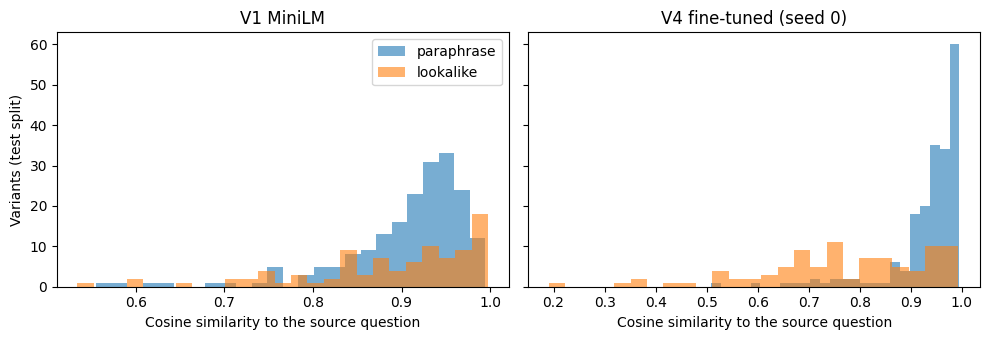

In [16]:
# Evaluate V4 exactly like V1 (threshold chosen on validation, reported on test)
rows4 = []
for seed in (0, 1, 2):
    key = f"v4_s{seed}"
    sv, st = make_stream(seed, "val"), make_stream(seed, "test")
    cv = reuse.sweep(sv, sim_for(sv, key), THRESH)
    curves[("V4 fine-tuned MiniLM", seed)] = cv
    t = reuse.pick_threshold(cv, TARGET)
    rows4.append({"rule": "V4 fine-tuned MiniLM", "seed": seed, "threshold": t,
                  **reuse.summarise(reuse.simulate(st, sim_for(st, key), t))})
res = pd.concat([res[res["rule"] != "V4 fine-tuned MiniLM"], pd.DataFrame(rows4)], ignore_index=True)
res.to_csv(MET / "task1_results_by_seed.csv", index=False)
display(res.groupby("rule")[["threshold", "calls_saved", "unsafe_reuse", "safe_recall"]].agg(["mean", "std"]).round(3))

# Best operating points on validation (seed 0): lowest unsafe reuse while saving at least 10% of calls
pts = []
for label in ["V1 MiniLM", "V1 bge", "V2 ensemble", "V4 fine-tuned MiniLM"]:
    cv = curves[(label, 0)]
    ok = cv[cv["calls_saved"] >= 0.10]
    best = ok.sort_values("unsafe_reuse").iloc[0] if len(ok) else None
    pts.append({"rule": label, "threshold": None if best is None else best["threshold"],
                "calls_saved": None if best is None else round(best["calls_saved"], 3),
                "unsafe_reuse": None if best is None else round(best["unsafe_reuse"], 3)})
display(pd.DataFrame(pts))

# Same similarity histogram, V4 vs V1, on test-split variants only (never seen in training)
te = set(q.loc[q["split_s0"] == "test", "qid"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, key) in zip(axes, [("V1 MiniLM", "minilm"), ("V4 fine-tuned (seed 0)", "v4_s0")]):
    for kind in ("paraphrase", "lookalike"):
        vv = var[(var["kind"] == kind) & var["qid"].isin(te)]
        ax.hist([float(EMB[key][a] @ EMB[key][b]) for a, b in zip(vv["vid"], vv["qid"])], bins=25, alpha=.6, label=kind)
    ax.set_title(name); ax.set_xlabel("Cosine similarity to the source question")
axes[0].set_ylabel("Variants (test split)"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "task1_v4_similarity.png", dpi=150)

In V1 MiniLM, paraphrases and look-alikes have almost the same similarity scores. V4 fine-tuned MiniLM moves most look-alikes below 0.9, but a small group stays above 0.95, next to the paraphrases. Taking for each rule the threshold with the lowest unsafe reuse on the seed-0 validation stream, V4 saves 39.9% of calls with 10.8% unsafe reuse, against 14.2% and 21.4% for V1 bge, the best untuned model. V4 halves unsafe reuse while saving nearly three times as many calls, but it is still far above the 2% target. The remaining errors are look-alikes that differ by one entity, date or number, which is what V5's explicit checks are meant to catch.

## 10. V5: entity guard

V5 adds an explicit check on top of a similarity rule: a cached answer is reused only if the query and the cached question mention the same named entities, dates and numbers (spaCy NER plus a regex for numbers). Otherwise the query goes to the LLM. The threshold is chosen on validation with the guard switched on, exactly as for V1–V4.

In [17]:
# V5: entity guard on top of V1 MiniLM, V1 bge and V4
import re, spacy
from dsa4.stream import answer_key
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

KEEP = {"PERSON", "ORG", "GPE", "LOC", "NORP", "FAC", "EVENT", "WORK_OF_ART", "PRODUCT", "LAW",
        "LANGUAGE", "DATE", "TIME", "CARDINAL", "ORDINAL", "QUANTITY", "MONEY", "PERCENT"}
NUM = re.compile(r"\d+(?:[.,]\d+)?")

def norm(s):
    s = re.sub(r"^(the|a|an)\s+", "", s.lower().strip())
    return re.sub(r"[^\w\s]", "", s).strip()

def extract(text, doc):
    e = {norm(x.text) for x in doc.ents if x.label_ in KEEP} | set(NUM.findall(text))
    return {x for x in e if x}

ENT = {}
texts_all = list(pd.unique(pd.concat([var["text"], q["question"]])))
for t, doc in zip(texts_all, nlp.pipe(texts_all, batch_size=256)):
    ENT[t] = extract(t, doc)

def ents(t):
    if t not in ENT:
        ENT[t] = extract(t, nlp(t))
    return ENT[t]

def simulate_rule(st, sim, t, check=None):
    """Replay the stream exactly like reuse.simulate, but reuse the closest cached entry only if
    its similarity is >= t AND check(i, j) passes. A query that is not reused is answered by the
    LLM and stored. 'vetoed' marks queries whose similarity passed but the check said no."""
    keys = [answer_key(a, b, c) for a, b, c in zip(st["qid"], st["kind"], st["vid"])]
    stored, stored_keys, rows = [], set(), []
    for i in range(len(st)):
        if stored:
            s = sim[i, stored]
            k = int(np.argmax(s))
            best, j = float(s[k]), stored[k]
        else:
            best, j = -1.0, -1
        passes = j >= 0 and best >= t
        ok = passes and (check is None or check(i, j))
        rows.append({"reused": ok, "match": j if ok else -1, "best_sim": best,
                     "safe": (keys[i] == keys[j]) if ok else np.nan,
                     "could_reuse": keys[i] in stored_keys,
                     "vetoed": passes and not ok,
                     "vetoed_safe": passes and not ok and keys[i] == keys[j]})
        if not ok:
            stored.append(i)
            stored_keys.add(keys[i])
    return pd.DataFrame(rows, index=st.index)

# Sanity check: without a check, simulate_rule must give exactly the same result as reuse.simulate
_s = make_stream(0, "val"); _S = sim_for(_s, RULES["V1 bge"])
assert (simulate_rule(_s, _S, 0.93)["reused"].to_numpy() == reuse.simulate(_s, _S, 0.93)["reused"].to_numpy()).all()
print("simulate_rule matches reuse.simulate")

def ent_check(st):
    texts = st["text"].to_numpy()
    return lambda i, j: ents(texts[i]) == ents(texts[j])

THR = np.round(np.arange(0.70, 1.0001, 0.01), 2)

def curve(st, key, guard=True):
    S, chk = sim_for(st, key), (ent_check(st) if guard else None)
    return pd.DataFrame([{"threshold": t, **reuse.summarise(simulate_rule(st, S, t, chk))} for t in THR])

def bases(seed):
    return {"V1 MiniLM": RULES["V1 MiniLM"], "V1 bge": RULES["V1 bge"],
            "V4 fine-tuned MiniLM": f"v4_s{seed}"}

# Main result: threshold chosen on validation (<= 2% unsafe), reported on test, seeds 0-2
rows5 = []
for seed in (0, 1, 2):
    sv, st = make_stream(seed, "val"), make_stream(seed, "test")
    for label, key in bases(seed).items():
        cv = curve(sv, key)
        ok = cv[(cv["calls_saved"] > 0) & (cv["unsafe_reuse"] <= TARGET)]
        t = ok.sort_values("calls_saved").iloc[-1]["threshold"] if len(ok) else 1.01
        r = simulate_rule(st, sim_for(st, key), t, ent_check(st))
        rows5.append({"rule": "V5 guard + " + label, "seed": seed, "threshold": min(t, 1.0),
                      **reuse.summarise(r)})
res5 = pd.DataFrame(rows5)
res5.to_csv(MET / "task1_v5_results_by_seed.csv", index=False)
display(res5.groupby("rule")[["threshold", "calls_saved", "unsafe_reuse", "safe_recall"]]
        .agg(["mean", "std"]).round(3))

# Effect of the guard on the seed-0 validation stream, at each rule's lowest-unsafe threshold
sv = make_stream(0, "val")
pts = []
for label, key in bases(0).items():
    cv = curve(sv, key)
    cv = cv[cv["calls_saved"] > 0]
    t = cv.sort_values(["unsafe_reuse", "calls_saved"], ascending=[True, False]).iloc[0]["threshold"]
    S = sim_for(sv, key)
    s0 = reuse.summarise(simulate_rule(sv, S, t))
    r1 = simulate_rule(sv, S, t, ent_check(sv))
    s1 = reuse.summarise(r1)
    pts.append({"rule": label, "threshold": t,
                "calls_saved (no guard)": round(s0["calls_saved"], 3),
                "unsafe (no guard)": round(s0["unsafe_reuse"], 3),
                "calls_saved (guard)": round(s1["calls_saved"], 3),
                "unsafe (guard)": round(s1["unsafe_reuse"], 3),
                "blocked": int(r1["vetoed"].sum()),
                "blocked but safe": int(r1["vetoed_safe"].sum())})
display(pd.DataFrame(pts))

simulate_rule matches reuse.simulate


threshold        calls_saved         \
                                     mean    std        mean    std   
rule                                                                  
V5 guard + V1 MiniLM                1.000  0.000       0.000  0.000   
V5 guard + V1 bge                   0.997  0.006       0.005  0.009   
V5 guard + V4 fine-tuned MiniLM     1.000  0.000       0.000  0.000   

                                unsafe_reuse        safe_recall         
                                        mean    std        mean    std  
rule                                                                    
V5 guard + V1 MiniLM                   0.000  0.000       0.000  0.000  
V5 guard + V1 bge                      0.056  0.096       0.008  0.015  
V5 guard + V4 fine-tuned MiniLM        0.000  0.000       0.000  0.000

,rule,threshold,calls_saved (no guard),unsafe (no guard),calls_saved (guard),unsafe (guard),blocked,blocked but safe
0,V1 MiniLM,0.89,0.529,0.308,0.280,0.155,100,53
1,V1 bge,0.94,0.331,0.254,0.186,0.151,59,36
2,V4 fine-tuned MiniLM,0.94,0.399,0.108,0.270,0.094,53,46


With the threshold chosen on validation at ≤2% unsafe reuse, the entity guard does not make any rule usable: MiniLM and V4 still select a threshold of 1.0, and bge saves only 0.5% of calls with 5.6% unsafe reuse on test. At each rule's lowest-unsafe threshold on the seed-0 validation stream, the guard halves unsafe reuse for the untuned models (MiniLM 31.9% → 16.2%, bge 25.4% → 15.3%), but more than half of the reuses it blocks were safe, because paraphrases often name the same entity differently. On V4 the guard barely helps (10.8% → 9.9%) and 49 of its 56 blocks were safe: fine-tuning had already removed most entity-changed look-alikes, so the two methods catch the same errors. The remaining unsafe reuses involve changes NER does not detect, such as "country" → "continent" or "sticks" → "wires". A hard rule cannot balance these trade-offs, which motivates V6, a classifier that combines similarity with mismatch signals.

## 11. V6: gradient-boosting reuse classifier

V6 replaces the single similarity threshold with a classifier. For each query and its closest cached question, it combines MiniLM and bge similarity with mismatch signals: word overlap, words found in only one of the two questions, differing entities and numbers, and length ratio. It is trained on the training split to predict whether reuse is safe; its probability threshold is chosen on validation at ≤2% unsafe reuse and reported on test, as for V1–V5. V4 similarity is not used as a feature because V4 was trained on the same training pairs.

In [18]:
# V6: gradient-boosting reuse classifier (similarity + mismatch features)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

STOP = {"the", "a", "an", "of", "in", "on", "at", "to", "for", "by", "with", "and", "or", "is", "was",
        "are", "were", "be", "which", "what", "who", "whom", "whose", "when", "where", "how", "did",
        "does", "do", "that", "this", "from", "as", "it", "its", "his", "her", "their"}
WORD = re.compile(r"[a-z0-9]+")
def toks(t):
    return {w for w in WORD.findall(t.lower()) if w not in STOP}

FEATS = ["cos_minilm", "cos_bge", "jaccard", "only_query", "only_cached",
         "ent_diff", "ent_same", "num_diff", "len_ratio"]

def pair_features(st):
    texts, vids = st["text"].to_numpy(), st["vid"].to_numpy()
    def f(i, j):
        a, b = texts[i], texts[j]
        ta, tb, ea, eb = toks(a), toks(b), ents(a), ents(b)
        return [float(EMB["minilm"][vids[i]] @ EMB["minilm"][vids[j]]),
                float(EMB["bge"][vids[i]] @ EMB["bge"][vids[j]]),
                len(ta & tb) / max(1, len(ta | tb)), len(ta - tb), len(tb - ta),
                len(ea ^ eb), int(ea == eb),
                int(set(NUM.findall(a)) != set(NUM.findall(b))),
                min(len(a), len(b)) / max(len(a), len(b), 1)]
    return f

def labelled_pairs(st):
    """Every event paired with its most similar EARLIER event (V2 ensemble), labelled safe/unsafe."""
    keys = [answer_key(a, b, c) for a, b, c in zip(st["qid"], st["kind"], st["vid"])]
    S, f = sim_for(st, RULES["V2 ensemble"]), pair_features(st)
    X, y = [], []
    for i in range(1, len(st)):
        j = int(np.argmax(S[i, :i]))
        X.append(f(i, j))
        y.append(keys[i] == keys[j])
    return np.array(X), np.array(y)

def v6_check(st, clf, tau):
    f, memo = pair_features(st), {}
    def chk(i, j):
        if (i, j) not in memo:
            memo[(i, j)] = clf.predict_proba(np.array([f(i, j)]))[0, 1]
        return memo[(i, j)] >= tau
    return chk

TAUS = np.round(np.arange(0.50, 1.0001, 0.01), 2)
rows6 = []
for seed in (0, 1, 2):
    Xtr, ytr = labelled_pairs(make_stream(seed, "train"))
    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                         random_state=seed).fit(Xtr, ytr)
    sv, st = make_stream(seed, "val"), make_stream(seed, "test")
    Sv, St = sim_for(sv, RULES["V2 ensemble"]), sim_for(st, RULES["V2 ensemble"])
    cv = pd.DataFrame([{"tau": tau, **reuse.summarise(simulate_rule(sv, Sv, -1.0, v6_check(sv, clf, tau)))}
                       for tau in TAUS])
    ok = cv[(cv["calls_saved"] > 0) & (cv["unsafe_reuse"] <= TARGET)]
    tau = ok.sort_values("calls_saved").iloc[-1]["tau"] if len(ok) else 1.01
    rows6.append({"rule": "V6 gradient boosting", "seed": seed, "threshold": min(tau, 1.0),
                  **reuse.summarise(simulate_rule(st, St, -1.0, v6_check(st, clf, tau)))})
    if seed == 0:
        print(f"seed 0: trained on {len(ytr)} pairs ({ytr.mean():.1%} safe)")
        Xv, yv = labelled_pairs(sv)
        hard = Xv[:, 1] >= 0.8              # close pairs (bge >= 0.8): where the decision matters
        pv = clf.predict_proba(Xv)[:, 1]
        print(f"validation AUROC on close pairs ({hard.sum()} pairs)  V6: {roc_auc_score(yv[hard], pv[hard]):.3f}"
              f"   bge similarity alone: {roc_auc_score(yv[hard], Xv[hard, 1]):.3f}")
        nz = cv[cv["calls_saved"] > 0]
        if len(nz):
            low = nz.sort_values(["unsafe_reuse", "calls_saved"], ascending=[True, False]).iloc[0]
            print(f"lowest-unsafe point on seed-0 validation: tau={low['tau']}, "
                  f"calls_saved={low['calls_saved']:.3f}, unsafe_reuse={low['unsafe_reuse']:.3f}")
        imp = permutation_importance(clf, Xv[hard], yv[hard], n_repeats=10, random_state=0,
                                     scoring="roc_auc")
        display(pd.Series(imp.importances_mean, index=FEATS, name="importance (AUROC drop)")
                .sort_values(ascending=False).round(3))

res6 = pd.DataFrame(rows6)
res6.to_csv(MET / "task1_v6_results_by_seed.csv", index=False)
display(res6.groupby("rule")[["threshold", "calls_saved", "unsafe_reuse", "safe_recall"]]
        .agg(["mean", "std"]).round(3))

seed 0: trained on 1171 pairs (49.0% safe)
validation AUROC on close pairs (282 pairs)  V6: 0.960   bge similarity alone: 0.576
lowest-unsafe point on seed-0 validation: tau=0.94, calls_saved=0.430, unsafe_reuse=0.041


jaccard        0.059
only_cached    0.054
cos_bge        0.031
len_ratio      0.021
ent_diff       0.013
only_query     0.010
cos_minilm     0.009
num_diff       0.005
ent_same       0.000
Name: importance (AUROC drop), dtype: float64

threshold      calls_saved      unsafe_reuse       \
                          mean  std        mean  std         mean  std   
rule                                                                     
V6 gradient boosting       1.0  0.0         0.0  0.0          0.0  0.0   

                     safe_recall       
                            mean  std  
rule                                   
V6 gradient boosting         0.0  0.0

V6 also fails the strict 2% budget: no probability threshold reaches it on validation, so, like every other rule, it falls back to never reusing on test. It does, however, give by far the best trade-off. On the seed-0 validation stream, at its lowest-unsafe threshold, V6 saves 43.0% of calls with 4.1% unsafe reuse, compared with 39.9% and 10.8% for V4 and 33.1% and 25.4% for V1 bge. On close pairs (bge similarity ≥ 0.8), where the reuse decision is hard, the classifier separates safe from unsafe matches with AUROC 0.960, while bge similarity alone reaches only 0.576. Permutation importance shows why: the most useful features are word overlap (Jaccard) and the number of words found only in the cached question, which capture one-word changes such as "country" → "continent" that neither similarity nor NER detects. Similarity itself adds little once these mismatch signals are known. Reaching 2% would need either more training data (the full 2,000 questions) or per-entry thresholds with an error guarantee, which is the next variation (vCache).